In [ ]:
from google.colab import files
uploaded = files.upload()          # akan muncul tombol "Choose Files"
FILE = list(uploaded.keys())[0]    # nama file diambil otomatis
print("File terbaca:", FILE)

Saving data_pm25_padang.csv..csv to data_pm25_padang.csv..csv
File terbaca: data_pm25_padang.csv..csv


SEMUA HARI UJI
SVR   MAE 26.40 | RMSE 69.22 | MAPE 40.8%
Naive MAE 26.16 | RMSE 71.54 | MAPE 65.8%

HARI NORMAL (<= 50), 159 hari
SVR   MAE 3.64 | RMSE 5.24 | MAPE 31.6%
Naive MAE 8.52 | RMSE 41.89 | MAPE 62.7%


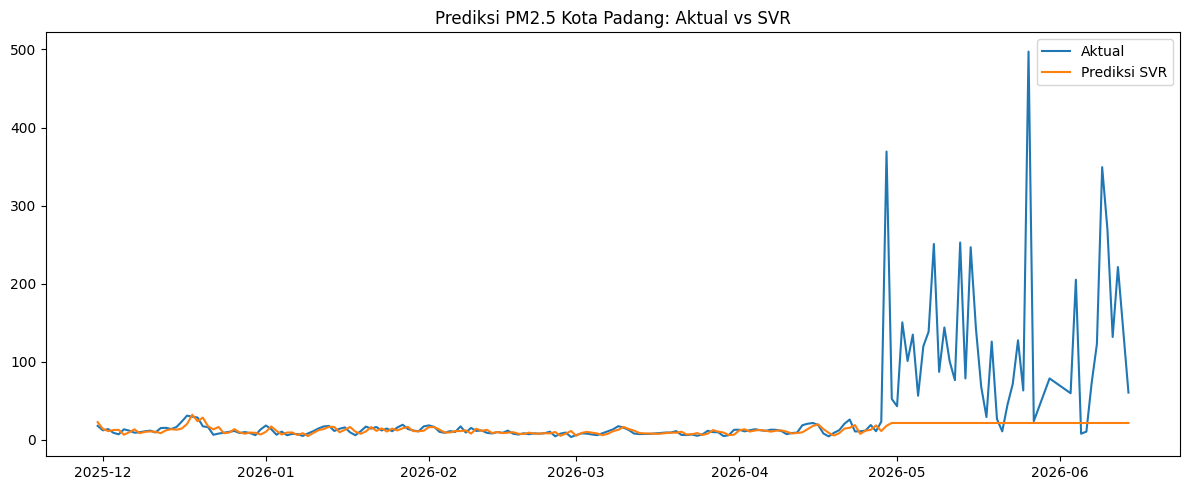

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error


MIN_COUNT = 12   # hari dengan pembacaan < 12 dianggap kurang andal
N_LAG = 7        # pakai 7 hari sebelumnya sebagai fitur

# 1. Baca data
df = pd.read_csv(FILE, sep=";", skiprows=1)
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")
df = df.sort_values("date").reset_index(drop=True)

# 2. Hari kurang andal -> kosongkan lalu isi dengan interpolasi
df.loc[df["count"] < MIN_COUNT, "median"] = np.nan
df["median"] = df["median"].interpolate().bfill()
y_all = df["median"]

# 3. Fitur lag
feat = pd.DataFrame({"y": y_all})
for i in range(1, N_LAG + 1):
    feat[f"lag_{i}"] = y_all.shift(i)
feat["date"] = df["date"]
feat = feat.dropna().reset_index(drop=True)

cols = [f"lag_{i}" for i in range(1, N_LAG + 1)]
split = int(len(feat) * 0.8)            # 80% latih, 20% uji, urut waktu
Xtr, Xte = feat[cols].iloc[:split], feat[cols].iloc[split:]
ytr = feat["y"].iloc[:split]
y_true = feat["y"].iloc[split:].values
tgl = feat["date"].iloc[split:]

# 4. Normalisasi dan latih SVR
sx, sy = StandardScaler(), StandardScaler()
Xtr_s = sx.fit_transform(Xtr)
Xte_s = sx.transform(Xte)
ytr_s = sy.fit_transform(ytr.values.reshape(-1, 1)).ravel()
model = SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale").fit(Xtr_s, ytr_s)
pred = sy.inverse_transform(model.predict(Xte_s).reshape(-1, 1)).ravel()

# 5. Pembanding sederhana: tebak "sama dengan kemarin"
naive = Xte["lag_1"].values

def evaluasi(a, p):
    return (mean_absolute_error(a, p),
            np.sqrt(mean_squared_error(a, p)),
            np.mean(np.abs((a - p) / a)) * 100)

print("SEMUA HARI UJI")
print("SVR   MAE %.2f | RMSE %.2f | MAPE %.1f%%" % evaluasi(y_true, pred))
print("Naive MAE %.2f | RMSE %.2f | MAPE %.1f%%" % evaluasi(y_true, naive))

normal = y_true <= 50
print(f"\nHARI NORMAL (<= 50), {normal.sum()} hari")
print("SVR   MAE %.2f | RMSE %.2f | MAPE %.1f%%" % evaluasi(y_true[normal], pred[normal]))
print("Naive MAE %.2f | RMSE %.2f | MAPE %.1f%%" % evaluasi(y_true[normal], naive[normal]))

# 6. Grafik
plt.figure(figsize=(12, 5))
plt.plot(tgl, y_true, label="Aktual")
plt.plot(tgl, pred, label="Prediksi SVR")
plt.title("Prediksi PM2.5 Kota Padang: Aktual vs SVR")
plt.legend(); plt.tight_layout()
plt.savefig("hasil_prediksi.png", dpi=150); plt.show()